# Langkah 1 — Buka notebook

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd

folder = "/content/drive/MyDrive/Data ML"

print(os.listdir(folder))

Mounted at /content/drive
['Provinsi.cpg', 'Provinsi.prj', 'Provinsi.dbf', 'Provinsi.shp', 'Provinsi.shx', 'fire_archive_SV-C2_821581.csv', 'fire_nrt_SV-C2_821581.csv', 'hotspot_kalimantan_tengah.csv', 'meteorologi_kalimantan_tengah.csv']


# Langkah 2 — Membaca dan memeriksa kedua dataset

In [ ]:
import pandas as pd

# Membaca dataset
hotspot = pd.read_csv(
    f"{folder}/hotspot_kalimantan_tengah.csv"
)

meteorologi = pd.read_csv(
    f"{folder}/meteorologi_kalimantan_tengah.csv"
)

# Pemeriksaan awal
print("=== DATA HOTSPOT ===")
print("Ukuran:", hotspot.shape)
print("Kolom:", hotspot.columns.tolist())
display(hotspot.head())

print("\n=== DATA METEOROLOGI ===")
print("Ukuran:", meteorologi.shape)
print("Kolom:", meteorologi.columns.tolist())
display(meteorologi.head())

=== DATA HOTSPOT ===
Ukuran: (178732, 15)
Kolom: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-3.37586,112.50913,332.88,0.40,0.37,2021-01-06,551,SNPP,SNPP,n,2,295.89,2.64,D,0.0
1,-3.06813,112.53498,332.70,0.39,0.37,2021-01-06,551,SNPP,SNPP,n,2,295.64,2.44,D,0.0
2,-0.99559,113.52280,341.73,0.41,0.61,2021-01-20,630,SNPP,SNPP,n,2,277.39,5.09,D,0.0
3,-2.55898,111.15220,333.39,0.43,0.38,2021-01-21,610,SNPP,SNPP,n,2,296.49,4.76,D,0.0
4,-2.55549,111.15167,335.33,0.43,0.38,2021-01-21,610,SNPP,SNPP,n,2,296.73,4.76,D,0.0



=== DATA METEOROLOGI ===
Ukuran: (10555, 6)
Kolom: ['tanggal', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M', 'lokasi']


,tanggal,T2M,RH2M,PRECTOTCORR,WS10M,lokasi
0,2021-01-01,25.87,90.30,5.21,0.52,Palangka Raya
1,2021-01-02,26.02,89.26,1.50,0.51,Palangka Raya
2,2021-01-03,26.45,88.98,9.02,0.72,Palangka Raya
3,2021-01-04,26.30,91.03,9.64,0.74,Palangka Raya
4,2021-01-05,25.69,92.79,5.07,0.55,Palangka Raya


# Langkah 3 — Cek kualitas kedua dataset

In [ ]:
# Konversi kolom tanggal
hotspot["acq_date"] = pd.to_datetime(hotspot["acq_date"])
meteorologi["tanggal"] = pd.to_datetime(meteorologi["tanggal"])

# Cek kualitas data hotspot
print("=== KUALITAS DATA HOTSPOT ===")
print("Missing value:", hotspot.isna().sum().sum())
print("Duplikat baris:", hotspot.duplicated().sum())
print("Periode:", hotspot["acq_date"].min(), "s.d.", hotspot["acq_date"].max())

print("\nRentang koordinat:")
print("Latitude:", hotspot["latitude"].min(), "s.d.", hotspot["latitude"].max())
print("Longitude:", hotspot["longitude"].min(), "s.d.", hotspot["longitude"].max())

# Cek kualitas data meteorologi
print("\n=== KUALITAS DATA METEOROLOGI ===")
print("Missing value:")
display(meteorologi.isna().sum())

print("Duplikat baris:", meteorologi.duplicated().sum())
print("Jumlah lokasi:", meteorologi["lokasi"].nunique())
print("Jumlah tanggal unik:", meteorologi["tanggal"].nunique())

print("\nJumlah data per lokasi:")
display(meteorologi.groupby("lokasi").agg(
    jumlah_baris=("tanggal", "size"),
    tanggal_awal=("tanggal", "min"),
    tanggal_akhir=("tanggal", "max"),
    tanggal_unik=("tanggal", "nunique")
))

=== KUALITAS DATA HOTSPOT ===
Missing value: 133004
Duplikat baris: 0
Periode: 2021-01-06 00:00:00 s.d. 2026-10-12 00:00:00

Rentang koordinat:
Latitude: -3.51689 s.d. -0.00031
Longitude: 110.75585 s.d. 115.71839

=== KUALITAS DATA METEOROLOGI ===
Missing value:


,0
tanggal,0
T2M,0
RH2M,0
PRECTOTCORR,0
WS10M,0
lokasi,0


Duplikat baris: 0
Jumlah lokasi: 5
Jumlah tanggal unik: 2111

Jumlah data per lokasi:


,jumlah_baris,tanggal_awal,tanggal_akhir,tanggal_unik
lokasi,,,,
Kuala Kapuas,2111,2021-01-01,2026-10-12,2111
Muara Teweh,2111,2021-01-01,2026-10-12,2111
Palangka Raya,2111,2021-01-01,2026-10-12,2111
Pangkalan Bun,2111,2021-01-01,2026-10-12,2111
Sampit,2111,2021-01-01,2026-10-12,2111


# Langkah 4 — Cari kolom hotspot yang memiliki nilai kosong

In [ ]:
# Jumlah dan persentase missing value per kolom
missing = pd.DataFrame({
    "jumlah_missing": hotspot.isna().sum(),
    "persentase_missing": (
        hotspot.isna().mean() * 100
    ).round(2)
})

display(missing[missing["jumlah_missing"] > 0].sort_values(
    "jumlah_missing", ascending=False
))

,jumlah_missing,persentase_missing
type,133004,74.42


# Langkah 5 — Agregasi data hotspot menjadi jumlah deteksi harian.

In [ ]:
# Hitung jumlah deteksi hotspot per tanggal
hotspot_harian = (
    hotspot.groupby("acq_date")
    .size()
    .reset_index(name="jumlah_hotspot")
)

# Samakan nama kolom tanggal
hotspot_harian = hotspot_harian.rename(
    columns={"acq_date": "tanggal"}
)

print("Ukuran data hotspot harian:", hotspot_harian.shape)
print("Periode:", hotspot_harian["tanggal"].min(),
      "s.d.", hotspot_harian["tanggal"].max())

display(hotspot_harian.head(10))

print("\nStatistik jumlah deteksi hotspot per hari:")
display(hotspot_harian["jumlah_hotspot"].describe())

Ukuran data hotspot harian: (1308, 2)
Periode: 2021-01-06 00:00:00 s.d. 2026-10-12 00:00:00


,tanggal,jumlah_hotspot
0,2021-01-06,2
1,2021-01-20,1
2,2021-01-21,3
3,2021-02-05,2
4,2021-02-06,1
5,2021-02-10,2
6,2021-02-11,4
7,2021-02-12,1
8,2021-02-13,1
9,2021-02-15,3



Statistik jumlah deteksi hotspot per hari:


,jumlah_hotspot
count,1308.000000
mean,136.645260
std,551.695238
min,1.000000
25%,2.000000
50%,5.000000
75%,19.000000
max,6417.000000


In [ ]:
# Buat rentang tanggal lengkap
rentang_tanggal = pd.date_range(
    start="2021-01-01",
    end="2026-10-12",
    freq="D"
)

# Lengkapi tanggal hotspot
hotspot_harian = (
    hotspot_harian
    .set_index("tanggal")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("tanggal")
    .reset_index()
)

# Pastikan jumlah hotspot bertipe integer
hotspot_harian["jumlah_hotspot"] = (
    hotspot_harian["jumlah_hotspot"].astype(int)
)

print("Jumlah baris:", len(hotspot_harian))
print("Tanggal awal:", hotspot_harian["tanggal"].min())
print("Tanggal akhir:", hotspot_harian["tanggal"].max())
print("Jumlah hari dengan deteksi:",
      (hotspot_harian["jumlah_hotspot"] > 0).sum())
print("Jumlah hari tanpa deteksi:",
      (hotspot_harian["jumlah_hotspot"] == 0).sum())

display(hotspot_harian.head(10))

Jumlah baris: 2111
Tanggal awal: 2021-01-01 00:00:00
Tanggal akhir: 2026-10-12 00:00:00
Jumlah hari dengan deteksi: 1308
Jumlah hari tanpa deteksi: 803


,tanggal,jumlah_hotspot
0,2021-01-01,0
1,2021-01-02,0
2,2021-01-03,0
3,2021-01-04,0
4,2021-01-05,0
5,2021-01-06,2
6,2021-01-07,0
7,2021-01-08,0
8,2021-01-09,0
9,2021-01-10,0


# Langkah 7 — Agregasi data meteorologi

In [ ]:
# Pastikan kolom tanggal bertipe datetime
meteorologi["tanggal"] = pd.to_datetime(meteorologi["tanggal"])

# Ringkas lima lokasi menjadi satu nilai per tanggal
meteorologi_harian = (
    meteorologi
    .groupby("tanggal", as_index=False)
    .agg({
        "T2M": "mean",
        "RH2M": "mean",
        "PRECTOTCORR": "mean",
        "WS10M": "mean"
    })
)

# Pembulatan dua angka desimal
kolom_cuaca = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]
meteorologi_harian[kolom_cuaca] = (
    meteorologi_harian[kolom_cuaca].round(2)
)

print("Ukuran data meteorologi harian:", meteorologi_harian.shape)
print("Tanggal awal:", meteorologi_harian["tanggal"].min())
print("Tanggal akhir:", meteorologi_harian["tanggal"].max())

display(meteorologi_harian.head(10))

Ukuran data meteorologi harian: (2111, 5)
Tanggal awal: 2021-01-01 00:00:00
Tanggal akhir: 2026-10-12 00:00:00


,tanggal,T2M,RH2M,PRECTOTCORR,WS10M
0,2021-01-01,25.95,90.14,5.74,0.81
1,2021-01-02,26.13,89.35,3.76,0.86
2,2021-01-03,26.40,89.01,5.52,1.00
3,2021-01-04,26.33,90.49,14.43,0.94
4,2021-01-05,26.10,89.63,11.35,0.80
5,2021-01-06,26.41,88.38,2.41,0.59
6,2021-01-07,25.79,91.97,16.36,0.92
7,2021-01-08,26.13,89.02,7.77,0.95
8,2021-01-09,26.31,91.07,32.29,0.96
9,2021-01-10,25.94,92.53,21.63,0.92


# Langkah 8 — Merge data hotspot dan meteorologi

In [ ]:
# Gabungkan berdasarkan tanggal
df_final = pd.merge(
    hotspot_harian,
    meteorologi_harian,
    on="tanggal",
    how="inner",
    validate="one_to_one"
)

# Urutkan berdasarkan tanggal
df_final = df_final.sort_values("tanggal").reset_index(drop=True)

print("Ukuran dataset final:", df_final.shape)
print("\n5 data pertama:")
display(df_final.head())

print("\nInformasi dataset:")
df_final.info()

print("\nMissing value:")
display(df_final.isna().sum())

print("\nStatistik deskriptif:")
display(df_final.describe())

Ukuran dataset final: (2111, 6)

5 data pertama:


,tanggal,jumlah_hotspot,T2M,RH2M,PRECTOTCORR,WS10M
0,2021-01-01,0,25.95,90.14,5.74,0.81
1,2021-01-02,0,26.13,89.35,3.76,0.86
2,2021-01-03,0,26.40,89.01,5.52,1.00
3,2021-01-04,0,26.33,90.49,14.43,0.94
4,2021-01-05,0,26.10,89.63,11.35,0.80



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   tanggal         2111 non-null   datetime64[ns]
 1   jumlah_hotspot  2111 non-null   int64         
 2   T2M             2111 non-null   float64       
 3   RH2M            2111 non-null   float64       
 4   PRECTOTCORR     2111 non-null   float64       
 5   WS10M           2111 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 99.1 KB

Missing value:


,0
tanggal,0
jumlah_hotspot,0
T2M,0
RH2M,0
PRECTOTCORR,0
WS10M,0



Statistik deskriptif:


,tanggal,jumlah_hotspot,T2M,RH2M,PRECTOTCORR,WS10M
count,2111,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,2023-11-22 00:00:00,84.666982,25.327774,85.732582,6.885140,-0.567793
min,2021-01-01 00:00:00,0.000000,-999.000000,-999.000000,-999.000000,-999.000000
25%,2022-06-12 12:00:00,0.000000,26.300000,85.950000,1.855000,0.750000
50%,2023-11-22 00:00:00,1.000000,26.760000,87.900000,5.960000,0.830000
75%,2025-05-02 12:00:00,7.000000,27.250000,89.885000,12.025000,0.950000
max,2026-10-12 00:00:00,6417.000000,29.460000,96.230000,120.670000,1.410000
std,NaN,439.246814,38.658440,41.162210,39.056779,37.674731


# Langkah 9 — Periksa dan tangani nilai -999

In [ ]:
# Periksa jumlah nilai -999 pada setiap variabel
kolom_cuaca = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

print("Jumlah nilai -999 sebelum penanganan:")
print((df_final[kolom_cuaca] == -999).sum())

# Ganti kode -999 menjadi NaN
df_final[kolom_cuaca] = df_final[kolom_cuaca].replace(-999, float("nan"))

print("\nJumlah missing value setelah penggantian:")
print(df_final[kolom_cuaca].isna().sum())

print("\nStatistik setelah nilai -999 dikeluarkan:")
display(df_final[kolom_cuaca].describe())

Jumlah nilai -999 sebelum penanganan:
T2M            3
RH2M           3
PRECTOTCORR    3
WS10M          3
dtype: int64

Jumlah missing value setelah penggantian:
T2M            3
RH2M           3
PRECTOTCORR    3
WS10M          3
dtype: int64

Statistik setelah nilai -999 dikeluarkan:


,T2M,RH2M,PRECTOTCORR,WS10M
count,2108.000000,2108.000000,2108.000000,2108.000000
mean,26.785546,87.276319,8.316665,0.853126
std,0.729218,4.361081,9.215218,0.148342
min,24.590000,64.140000,0.000000,0.500000
25%,26.300000,85.960000,1.867500,0.750000
50%,26.760000,87.900000,5.980000,0.830000
75%,27.250000,89.890000,12.032500,0.950000
max,29.460000,96.230000,120.670000,1.410000


# Langkah 10 — Tangani missing value meteorologi

In [ ]:
# Urutkan berdasarkan tanggal
df_final = df_final.sort_values("tanggal").reset_index(drop=True)

kolom_cuaca = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

# Simpan jumlah missing sebelum penanganan
print("Missing sebelum interpolasi:")
print(df_final[kolom_cuaca].isna().sum())

# Interpolasi berdasarkan urutan waktu
df_final = df_final.set_index("tanggal")

df_final[kolom_cuaca] = df_final[kolom_cuaca].interpolate(
    method="time",
    limit_area="inside"
)

df_final = df_final.reset_index()

print("\nMissing setelah interpolasi:")
print(df_final[kolom_cuaca].isna().sum())

print("\nUkuran dataset:", df_final.shape)
print("\nStatistik meteorologi:")
display(df_final[kolom_cuaca].describe())

Missing sebelum interpolasi:
T2M            3
RH2M           3
PRECTOTCORR    3
WS10M          3
dtype: int64

Missing setelah interpolasi:
T2M            3
RH2M           3
PRECTOTCORR    3
WS10M          3
dtype: int64

Ukuran dataset: (2111, 6)

Statistik meteorologi:


,T2M,RH2M,PRECTOTCORR,WS10M
count,2108.000000,2108.000000,2108.000000,2108.000000
mean,26.785546,87.276319,8.316665,0.853126
std,0.729218,4.361081,9.215218,0.148342
min,24.590000,64.140000,0.000000,0.500000
25%,26.300000,85.960000,1.867500,0.750000
50%,26.760000,87.900000,5.980000,0.830000
75%,27.250000,89.890000,12.032500,0.950000
max,29.460000,96.230000,120.670000,1.410000


# Langkah 10A — Cari tanggal yang masih missing

In [ ]:
kolom_cuaca = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

baris_missing = df_final[
    df_final[kolom_cuaca].isna().any(axis=1)
]

display(baris_missing[["tanggal"] + kolom_cuaca])

print("Jumlah baris yang masih missing:", len(baris_missing))

,tanggal,T2M,RH2M,PRECTOTCORR,WS10M
2108,2026-10-10,NaN,NaN,NaN,NaN
2109,2026-10-11,NaN,NaN,NaN,NaN
2110,2026-10-12,NaN,NaN,NaN,NaN


Jumlah baris yang masih missing: 3


# Langkah 10B — Ambil ulang data meteorologi untuk tiga tanggal terakhir

In [ ]:
import requests
import pandas as pd

lokasi = {
    "Palangka Raya": (-2.21, 113.92),
    "Sampit": (-2.53, 112.95),
    "Pangkalan Bun": (-2.68, 111.62),
    "Muara Teweh": (-0.95, 114.89),
    "Kuala Kapuas": (-3.01, 114.39)
}

parameter = "T2M,RH2M,PRECTOTCORR,WS10M"
hasil_cek = []

for nama, (lat, lon) in lokasi.items():
    url = "https://power.larc.nasa.gov/api/temporal/daily/point"

    params = {
        "parameters": parameter,
        "community": "SB",
        "latitude": lat,
        "longitude": lon,
        "start": "20261010",
        "end": "20261012",
        "format": "JSON"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()["properties"]["parameter"]

    for tanggal in data["T2M"]:
        hasil_cek.append({
            "lokasi": nama,
            "tanggal": tanggal,
            "T2M": data["T2M"][tanggal],
            "RH2M": data["RH2M"][tanggal],
            "PRECTOTCORR": data["PRECTOTCORR"][tanggal],
            "WS10M": data["WS10M"][tanggal]
        })

cek_terbaru = pd.DataFrame(hasil_cek)
display(cek_terbaru)

,lokasi,tanggal,T2M,RH2M,PRECTOTCORR,WS10M
0,Palangka Raya,20261010,-999.0,-999.0,-999.0,-999.0
1,Palangka Raya,20261011,-999.0,-999.0,-999.0,-999.0
2,Palangka Raya,20261012,-999.0,-999.0,-999.0,-999.0
3,Sampit,20261010,-999.0,-999.0,-999.0,-999.0
4,Sampit,20261011,-999.0,-999.0,-999.0,-999.0
5,Sampit,20261012,-999.0,-999.0,-999.0,-999.0
6,Pangkalan Bun,20261010,-999.0,-999.0,-999.0,-999.0
7,Pangkalan Bun,20261011,-999.0,-999.0,-999.0,-999.0
8,Pangkalan Bun,20261012,-999.0,-999.0,-999.0,-999.0
9,Muara Teweh,20261010,-999.0,-999.0,-999.0,-999.0


# Langkah 10C — Batasi dataset sampai 9 Oktober 2026

In [ ]:
# Ambil hanya tanggal dengan data meteorologi lengkap
df_final = df_final[
    df_final["tanggal"] <= "2026-10-09"
].copy()

df_final = df_final.sort_values("tanggal").reset_index(drop=True)

# Validasi hasil
kolom_cuaca = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

print("Ukuran dataset:", df_final.shape)
print("Tanggal awal:", df_final["tanggal"].min())
print("Tanggal akhir:", df_final["tanggal"].max())

print("\nMissing value:")
print(df_final.isna().sum())

print("\nNilai -999:")
print((df_final[kolom_cuaca] == -999).sum())

Ukuran dataset: (2108, 6)
Tanggal awal: 2021-01-01 00:00:00
Tanggal akhir: 2026-10-09 00:00:00

Missing value:
tanggal           0
jumlah_hotspot    0
T2M               0
RH2M              0
PRECTOTCORR       0
WS10M             0
dtype: int64

Nilai -999:
T2M            0
RH2M           0
PRECTOTCORR    0
WS10M          0
dtype: int64


# Langkah 11 — Membuat label target

Kita gunakan aturan berikut:
- 1 = ada deteksi hotspot pada hari tersebut (jumlah_hotspot > 0).
- 0 = tidak ada deteksi hotspot yang tercatat (jumlah_hotspot = 0).

In [ ]:
# Membuat label klasifikasi
df_final["kejadian_hotspot"] = (
    df_final["jumlah_hotspot"] > 0
).astype(int)

# Menghitung distribusi kelas
distribusi = df_final["kejadian_hotspot"].value_counts().sort_index()

ringkasan = pd.DataFrame({
    "jumlah_hari": distribusi,
    "persentase": (
        distribusi / len(df_final) * 100
    ).round(2)
})

ringkasan.index = [
    "Tidak ada deteksi hotspot (0)",
    "Ada deteksi hotspot (1)"
]

print("Distribusi kelas target:")
display(ringkasan)

print("\nContoh dataset:")
display(df_final.head(10))

Distribusi kelas target:


,jumlah_hari,persentase
Tidak ada deteksi hotspot (0),803,38.09
Ada deteksi hotspot (1),1305,61.91



Contoh dataset:


,tanggal,jumlah_hotspot,T2M,RH2M,PRECTOTCORR,WS10M,kejadian_hotspot
0,2021-01-01,0,25.95,90.14,5.74,0.81,0
1,2021-01-02,0,26.13,89.35,3.76,0.86,0
2,2021-01-03,0,26.40,89.01,5.52,1.00,0
3,2021-01-04,0,26.33,90.49,14.43,0.94,0
4,2021-01-05,0,26.10,89.63,11.35,0.80,0
5,2021-01-06,2,26.41,88.38,2.41,0.59,1
6,2021-01-07,0,25.79,91.97,16.36,0.92,0
7,2021-01-08,0,26.13,89.02,7.77,0.95,0
8,2021-01-09,0,26.31,91.07,32.29,0.96,0
9,2021-01-10,0,25.94,92.53,21.63,0.92,0


# Langkah 12 — Membuat target prediksi H+1

In [ ]:
# Target = kejadian hotspot pada hari berikutnya
df_final["target_hari_berikutnya"] = (
    df_final["kejadian_hotspot"].shift(-1)
)

# Baris terakhir tidak memiliki target hari berikutnya
df_model = df_final.dropna(
    subset=["target_hari_berikutnya"]
).copy()

df_model["target_hari_berikutnya"] = (
    df_model["target_hari_berikutnya"].astype(int)
)

print("Ukuran dataset modeling:", df_model.shape)
print("\nDistribusi target hari berikutnya:")
display(
    df_model["target_hari_berikutnya"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Tidak ada deteksi hotspot besok",
        1: "Ada deteksi hotspot besok"
    })
)

display(df_model[
    ["tanggal", "T2M", "RH2M", "PRECTOTCORR",
     "WS10M", "kejadian_hotspot", "target_hari_berikutnya"]
].head(10))

Ukuran dataset modeling: (2107, 8)

Distribusi target hari berikutnya:


,count
target_hari_berikutnya,
Tidak ada deteksi hotspot besok,802
Ada deteksi hotspot besok,1305


,tanggal,T2M,RH2M,PRECTOTCORR,WS10M,kejadian_hotspot,target_hari_berikutnya
0,2021-01-01,25.95,90.14,5.74,0.81,0,0
1,2021-01-02,26.13,89.35,3.76,0.86,0,0
2,2021-01-03,26.40,89.01,5.52,1.00,0,0
3,2021-01-04,26.33,90.49,14.43,0.94,0,0
4,2021-01-05,26.10,89.63,11.35,0.80,0,1
5,2021-01-06,26.41,88.38,2.41,0.59,1,0
6,2021-01-07,25.79,91.97,16.36,0.92,0,0
7,2021-01-08,26.13,89.02,7.77,0.95,0,0
8,2021-01-09,26.31,91.07,32.29,0.96,0,0
9,2021-01-10,25.94,92.53,21.63,0.92,0,0


# Langkah 13 — Membagi data training dan testing secara kronologis

In [ ]:
from sklearn.model_selection import train_test_split

# Fitur meteorologi
fitur = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

X = df_model[fitur]
y = df_model["target_hari_berikutnya"]

# Pembagian kronologis 80:20
batas = int(len(df_model) * 0.8)

X_train = X.iloc[:batas].copy()
X_test = X.iloc[batas:].copy()

y_train = y.iloc[:batas].copy()
y_test = y.iloc[batas:].copy()

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nPeriode training:")
print(df_model["tanggal"].iloc[0], "s.d.",
      df_model["tanggal"].iloc[batas - 1])

print("\nPeriode testing:")
print(df_model["tanggal"].iloc[batas], "s.d.",
      df_model["tanggal"].iloc[-1])

print("\nDistribusi target training:")
print(y_train.value_counts().sort_index())

print("\nDistribusi target testing:")
print(y_test.value_counts().sort_index())

Jumlah data training: 1685
Jumlah data testing: 422

Periode training:
2021-01-01 00:00:00 s.d. 2025-08-12 00:00:00

Periode testing:
2025-08-13 00:00:00 s.d. 2026-10-08 00:00:00

Distribusi target training:
target_hari_berikutnya
0     655
1    1030
Name: count, dtype: int64

Distribusi target testing:
target_hari_berikutnya
0    147
1    275
Name: count, dtype: int64


# Langkah 14 — Training dan evaluasi model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier
import pandas as pd

# Model 1: Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
prob_rf = rf.predict_proba(X_test)[:, 1]

# Model 2: XGBoost
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=1.0,
    eval_metric="logloss",
    random_state=42
)

xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
prob_xgb = xgb.predict_proba(X_test)[:, 1]

# Fungsi evaluasi
def evaluasi(nama, y_true, pred, prob):
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, prob)
    }

hasil = pd.DataFrame([
    evaluasi("Random Forest", y_test, pred_rf, prob_rf),
    evaluasi("XGBoost", y_test, pred_xgb, prob_xgb)
])

display(hasil.round(4))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Forest,0.6825,0.7743,0.7236,0.7481,0.8486
1,XGBoost,0.6445,0.7076,0.7745,0.7396,0.8553


# Langkah 15 — Buat ensemble gabungan

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Gabungkan probabilitas dari kedua model
prob_ensemble = (prob_rf + prob_xgb) / 2

# Gunakan threshold awal 0.5
pred_ensemble = (prob_ensemble >= 0.5).astype(int)

# Evaluasi ensemble
hasil_ensemble = pd.DataFrame([{
    "Model": "Ensemble RF + XGBoost",
    "Accuracy": accuracy_score(y_test, pred_ensemble),
    "Precision": precision_score(
        y_test, pred_ensemble, zero_division=0
    ),
    "Recall": recall_score(
        y_test, pred_ensemble, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, pred_ensemble, zero_division=0
    ),
    "PR-AUC": average_precision_score(
        y_test, prob_ensemble
    )
}])

display(hasil_ensemble.round(4))

print("Confusion matrix:")
print(confusion_matrix(y_test, pred_ensemble))

print("\nClassification report:")
print(classification_report(
    y_test, pred_ensemble, zero_division=0
))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Ensemble RF + XGBoost,0.673,0.7491,0.7491,0.7491,0.8533


Confusion matrix:
[[ 78  69]
 [ 69 206]]

Classification report:
              precision    recall  f1-score   support

           0       0.53      0.53      0.53       147
           1       0.75      0.75      0.75       275

    accuracy                           0.67       422
   macro avg       0.64      0.64      0.64       422
weighted avg       0.67      0.67      0.67       422



# Langkah 16 berikutnya: cek feature importance

In [ ]:
import pandas as pd

# Feature importance Random Forest
importance_rf = pd.DataFrame({
    "Variabel": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("=== FEATURE IMPORTANCE RANDOM FOREST ===")
display(importance_rf)

# Feature importance XGBoost
importance_xgb = pd.DataFrame({
    "Variabel": X_train.columns,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=False)

print("=== FEATURE IMPORTANCE XGBOOST ===")
display(importance_xgb)


=== FEATURE IMPORTANCE RANDOM FOREST ===


,Variabel,Importance
2,PRECTOTCORR,0.332577
1,RH2M,0.302203
0,T2M,0.199904
3,WS10M,0.165316


=== FEATURE IMPORTANCE XGBOOST ===


,Variabel,Importance
2,PRECTOTCORR,0.341698
1,RH2M,0.257699
3,WS10M,0.204927
0,T2M,0.195676


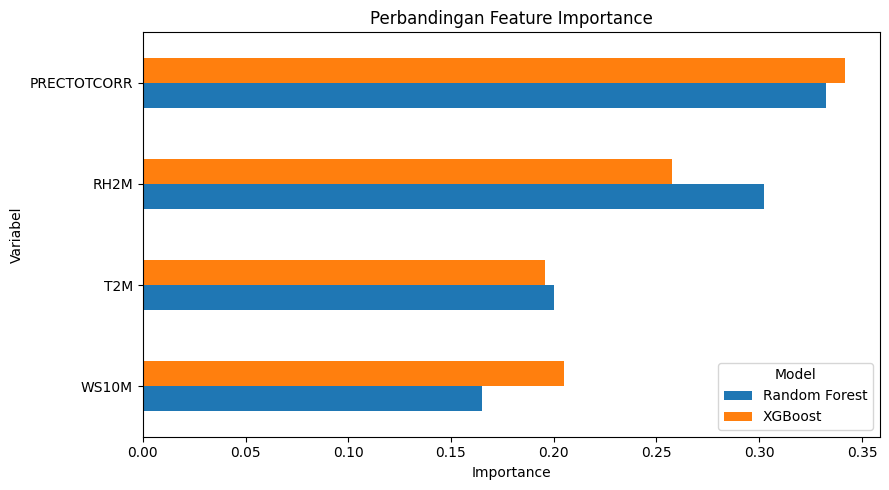

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

perbandingan_importance = pd.DataFrame({
    "Variabel": X_train.columns,
    "Random Forest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_
}).set_index("Variabel")

perbandingan_importance = perbandingan_importance.sort_values(
    "Random Forest"
)

perbandingan_importance.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Perbandingan Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Variabel")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# Langkah 16A — Tuning Random Forest dan XGBoost

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

# Validasi silang untuk data deret waktu
tscv = TimeSeriesSplit(n_splits=3)

# Ruang pencarian Random Forest
param_rf = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_rf,
    n_iter=20,
    scoring="average_precision",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best parameter Random Forest:")
print(rf_search.best_params_)
print("Best CV PR-AUC:", round(rf_search.best_score_, 4))


# Ruang pencarian XGBoost
param_xgb = {
    "n_estimators": randint(100, 401),
    "max_depth": randint(2, 7),
    "learning_rate": uniform(0.01, 0.19),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "min_child_weight": randint(1, 8),
    "reg_lambda": uniform(0.5, 4.5)
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_xgb,
    n_iter=20,
    scoring="average_precision",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("\nBest parameter XGBoost:")
print(xgb_search.best_params_)
print("Best CV PR-AUC:", round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameter Random Forest:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 5, 'class_weight': 'balanced'}
Best CV PR-AUC: 0.801
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best parameter XGBoost:
{'colsample_bytree': np.float64(0.7323674280979913), 'learning_rate': np.float64(0.015971545280479508), 'max_depth': 2, 'min_child_weight': 4, 'n_estimators': 195, 'reg_lambda': np.float64(3.6298223889175736), 'subsample': np.float64(0.7417994363217627)}
Best CV PR-AUC: 0.8038


# Langkah 16B — Evaluasi model hasil tuning

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Model terbaik hasil tuning
best_rf = rf_search.best_estimator_
best_xgb = xgb_search.best_estimator_

# Prediksi data testing
pred_rf_tuned = best_rf.predict(X_test)
prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

pred_xgb_tuned = best_xgb.predict(X_test)
prob_xgb_tuned = best_xgb.predict_proba(X_test)[:, 1]

# Gabungan probabilitas model terbaik
prob_ensemble_tuned = (
    prob_rf_tuned + prob_xgb_tuned
) / 2

pred_ensemble_tuned = (
    prob_ensemble_tuned >= 0.5
).astype(int)

# Fungsi evaluasi
def evaluasi_model(nama, y_true, pred, prob):
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_true, prob)
    }

hasil_tuning = pd.DataFrame([
    evaluasi_model(
        "Random Forest Tuned",
        y_test, pred_rf_tuned, prob_rf_tuned
    ),
    evaluasi_model(
        "XGBoost Tuned",
        y_test, pred_xgb_tuned, prob_xgb_tuned
    ),
    evaluasi_model(
        "Ensemble Tuned",
        y_test, pred_ensemble_tuned, prob_ensemble_tuned
    )
])

display(hasil_tuning.round(4))

print("\nConfusion matrix ensemble tuned:")
print(confusion_matrix(y_test, pred_ensemble_tuned))

print("\nClassification report ensemble tuned:")
print(classification_report(
    y_test, pred_ensemble_tuned, zero_division=0
))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Forest Tuned,0.6872,0.8069,0.6836,0.7402,0.8650
1,XGBoost Tuned,0.6825,0.7267,0.8218,0.7713,0.8603
2,Ensemble Tuned,0.6896,0.7647,0.7564,0.7605,0.8628



Confusion matrix ensemble tuned:
[[ 83  64]
 [ 67 208]]

Classification report ensemble tuned:
              precision    recall  f1-score   support

           0       0.55      0.56      0.56       147
           1       0.76      0.76      0.76       275

    accuracy                           0.69       422
   macro avg       0.66      0.66      0.66       422
weighted avg       0.69      0.69      0.69       422



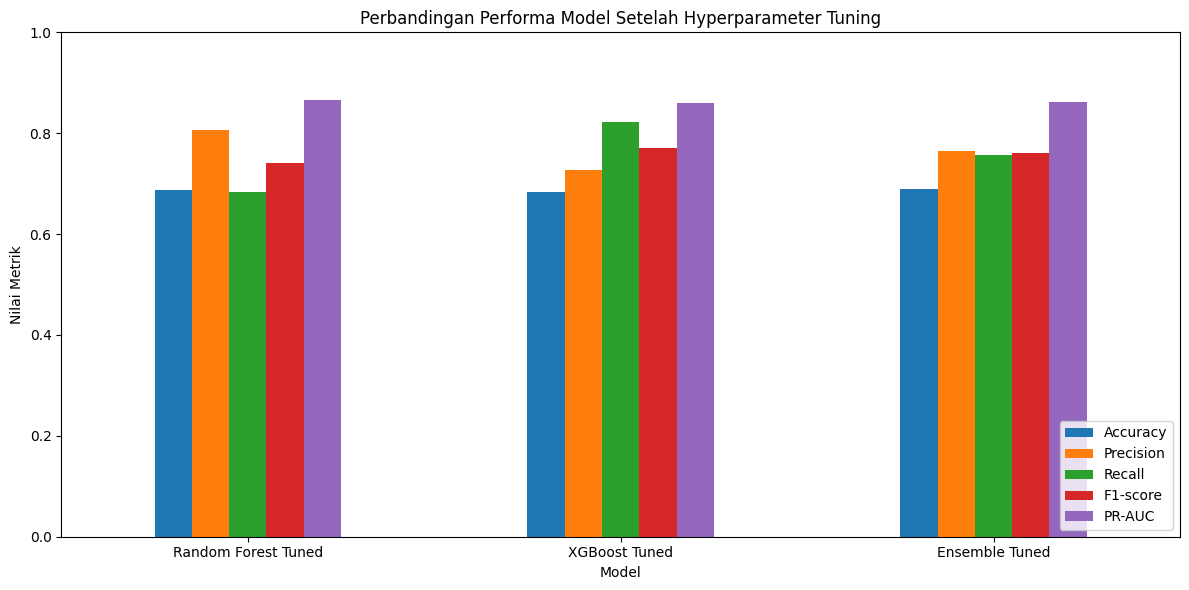

In [ ]:
import matplotlib.pyplot as plt

metrik = ["Accuracy", "Precision", "Recall", "F1-score", "PR-AUC"]

hasil_plot = hasil_tuning.set_index("Model")[metrik]

hasil_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Performa Model Setelah Hyperparameter Tuning")
plt.ylabel("Nilai Metrik")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

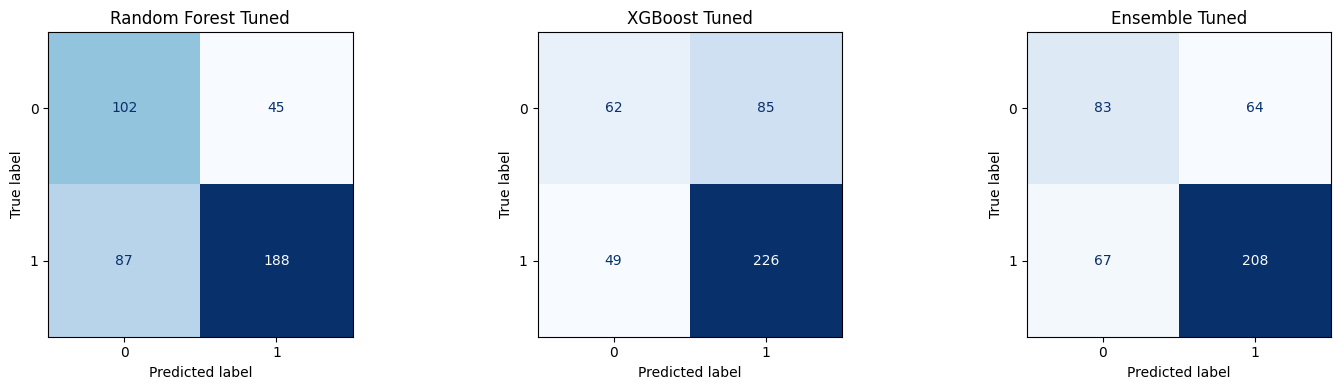

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

model_prediksi = [
    ("Random Forest Tuned", best_rf.predict(X_test)),
    ("XGBoost Tuned", best_xgb.predict(X_test)),
    ("Ensemble Tuned", (prob_ensemble_tuned >= 0.5).astype(int))
]

for ax, (nama, prediksi) in zip(axes, model_prediksi):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediksi,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(nama)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

tabel_evaluasi = pd.DataFrame({
    "Model": [
        "Random Forest Tuned",
        "XGBoost Tuned",
        "Ensemble Tuned"
    ],
    "Accuracy": [0.6872, 0.6825, 0.6896],
    "Precision": [0.8069, 0.7267, 0.7647],
    "Recall": [0.6836, 0.8218, 0.7564],
    "F1-score": [0.7402, 0.7713, 0.7605],
    "PR-AUC": [0.8650, 0.8603, 0.8628]
})

display(tabel_evaluasi.round(4))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Forest Tuned,0.6872,0.8069,0.6836,0.7402,0.8650
1,XGBoost Tuned,0.6825,0.7267,0.8218,0.7713,0.8603
2,Ensemble Tuned,0.6896,0.7647,0.7564,0.7605,0.8628
